# Boston Airbnb Pricing: Predictive Analytics for Hosts

**Goal.** Recommend a nightly price for a Boston Airbnb listing, based on what comparable listings charge today.

**Approach.**
1. Decide which data is needed and which columns are useful, leaky or empty.
2. **Pre-check the data** (duplicates, impossible values, inconsistent fields, locations, rare categories) and clean it.
3. Explore it, and engineer features a host can actually provide.
4. **Screen the variables**: rank them by correlation with price, check collinearity (VIF) and leakage, and keep only the ones that pass.
5. Train and compare several predictive-analytics methods:
   * **Baseline**: median price for the same neighbourhood and room type
   * **Linear Regression** (ordinary least squares)
   * **Lasso Regression** (L1-regularised linear model)
   * **Random Forest** (bagged decision trees)
   * **Gradient Boosting** (boosted decision trees)
6. Evaluate the models with cross-validation and a held-out test set (split **by host**, so no host appears in both), and pick the best one for pricing.
7. Export the models so the portfolio interface (`interface/index.html`) can price a listing in the browser.

**Source:** Inside Airbnb snapshot of Boston (`listings.csv`, `neighbourhoods.csv`, `neighbourhoods.geojson`).

In [1]:
import json, re, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sys
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, KFold, cross_val_score, GridSearchCV
from sklearn.feature_selection import mutual_info_regression
from sklearn.linear_model import LinearRegression, LassoCV, lasso_path
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

DATA = Path("../data")
OUT = Path("../interface")
SEED = 42
sys.path.insert(0, "../src")
import pricing_features as pf   # shared pre-check, cleaning and feature code (also used by Phase 2)

## 1. What data do we need?

Three files are provided:

| File | Content | Use |
|---|---|---|
| `listings.csv` | One row per active listing (4,368 rows, 19 columns) | **Main modelling table.** `price` is the target. |
| `neighbourhoods.csv` | The 25 official Boston neighbourhoods | Lookup and validation of the `neighbourhood` category |
| `neighbourhoods.geojson` | Neighbourhood boundary polygons | Maps, and the clickable location picker in the interface |

The table below lists each column in `listings.csv` and whether the model uses it.

In [2]:
listings = pd.read_csv(DATA / "listings.csv")
hoods = pd.read_csv(DATA / "neighbourhoods.csv")
geo = json.loads((DATA / "neighbourhoods.geojson").read_text())

decision = {
    "id": ("Drop", "Identifier only"),
    "name": ("Feature source", "Title text -> bedrooms, studio, amenity keywords"),
    "host_id": ("Drop", "Identifier; would let the model memorise hosts"),
    "host_profile_id": ("Drop", "Identifier"),
    "host_name": ("Drop", "Personal data, no pricing signal"),
    "neighbourhood_group": ("Drop", "100% empty for Boston"),
    "neighbourhood": ("Feature", "Location category (one-hot)"),
    "latitude": ("Feature", "Fine-grained location; also distance to downtown"),
    "longitude": ("Feature", "Fine-grained location"),
    "room_type": ("Feature", "Entire home / private / hotel / shared"),
    "price": ("TARGET", "Nightly price in USD (log-transformed)"),
    "minimum_nights": ("Feature", "Short-stay vs monthly-rental strategy"),
    "number_of_reviews": ("Feature", "Track record / popularity"),
    "last_review": ("Drop", "Mostly duplicated by reviews_per_month; date"),
    "reviews_per_month": ("Feature", "Demand proxy (NaN -> 0)"),
    "calculated_host_listings_count": ("Feature", "Professional vs casual host"),
    "availability_365": ("Feature", "How many days the host opens the calendar"),
    "number_of_reviews_ltm": ("Feature", "Recent demand (last 12 months)"),
    "license": ("Feature source", "Licensed / exempt / none flags"),
}
inventory = pd.DataFrame({
    "dtype": listings.dtypes.astype(str),
    "missing_%": (listings.isna().mean() * 100).round(1),
    "example": listings.iloc[1],
})
inventory["decision"] = [decision[c][0] for c in inventory.index]
inventory["reason"] = [decision[c][1] for c in inventory.index]
print(listings.shape, "| official neighbourhoods:", len(hoods), "| polygons:", len(geo["features"]))
inventory

(4368, 19) | official neighbourhoods: 26 | polygons: 26


,dtype,missing_%,example,decision,reason
id,int64,0.0,5506,Drop,Identifier only
name,str,0.0,** Fort Hill Inn Private! Minutes to center!**,Feature source,"Title text -> bedrooms, studio, amenity keywords"
host_id,int64,0.0,8229,Drop,Identifier; would let the model memorise hosts
host_profile_id,int64,0.0,1462506610204730632,Drop,Identifier
host_name,str,0.0,Terry,Drop,"Personal data, no pricing signal"
neighbourhood_group,float64,100.0,NaN,Drop,100% empty for Boston
neighbourhood,str,0.0,Roxbury,Feature,Location category (one-hot)
latitude,float64,0.0,42.32844,Feature,Fine-grained location; also distance to downtown
longitude,float64,0.0,-71.09581,Feature,Fine-grained location
room_type,str,0.0,Entire home/apt,Feature,Entire home / private / hotel / shared


**Data we would add next, if available.** The detailed Inside Airbnb `listings.csv.gz` has bedrooms, bathrooms, accommodates, amenities and review scores, and `calendar.csv` has occupancy and seasonality. They would improve accuracy a lot. This summary file has none of them, so we pull the strongest of those signals (bedroom count, studio, amenities) out of the listing **title**.

## 2. Data pre-check and cleaning

Before any modelling, every row goes through the checks in `src/pricing_features.py::precheck`. Each check reports how many rows it affects and what was done. Rules were chosen from the evidence, not by default:
* **Calendar closed (availability 0)** looks like a stale listing, but these listings have a median of 30+ reviews in the last 12 months. They are fully booked, not inactive, so they are **kept**.
* **Shared room** (4 listings) and **Leather District** (3) are too rare for any model to learn a reliable effect, so they are merged into the closest category (private room; adjacent Chinatown). Harbor Islands has no listings.

In [3]:
official = hoods["neighbourhood"]
n0 = len(listings)
n1 = int(listings["price"].notna().sum())
df, precheck_report = pf.precheck(listings, official, geo)
n2 = len(df)
upper = pf.PRICE_RANGE[1]
NEIGHBOURHOODS = pf.model_neighbourhoods(official)
a0 = df[df["availability_365"] == 0]
print(f"rows: {n0} raw -> {n1} priced -> {n2} after pre-check")
print(f"evidence for keeping availability-0 listings: median reviews in last 12 months = {a0['number_of_reviews_ltm'].median():.0f}")
precheck_report

rows: 4368 raw -> 3486 priced -> 3477 after pre-check
evidence for keeping availability-0 listings: median reviews in last 12 months = 34


,check,rows,action
0,Duplicate listing IDs,0,drop repeats
1,Missing price (inactive listing),882,drop: no target
2,Price outside $30-$2000,6,drop: extreme or erroneous price
3,"Exact duplicate posting (same host, title, loc...",3,drop copies
4,Neighbourhood not in official list,0,drop
5,Coordinates outside their neighbourhood boundary,0,flag (kept)
6,Reviews in last 12 months > total reviews,0,drop: inconsistent
7,Reviews per month missing (no reviews yet),482,fill with 0
8,Reviews per month > 0 with zero reviews,0,set to 0
9,Reviews per month above 15,5,cap at 15


## 3. Exploratory analysis

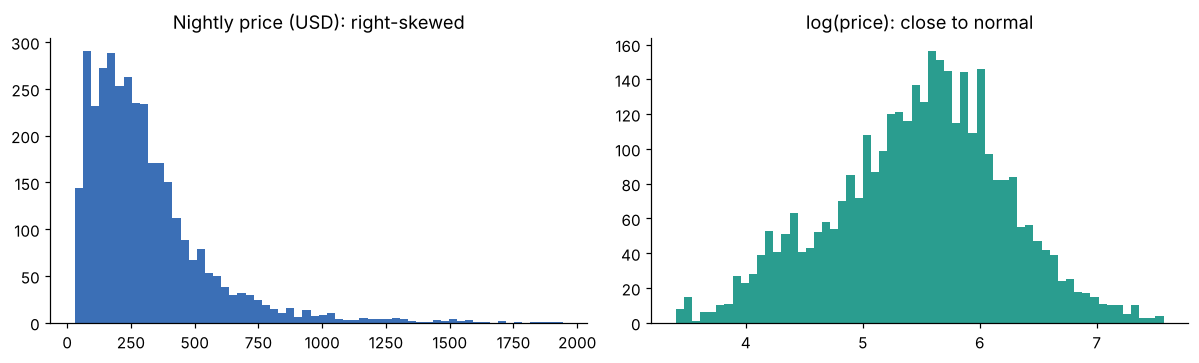

We model log(price): errors become relative (%), and linear models fit much better.


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ax[0].hist(df["price"], bins=60, color="#3b6fb6"); ax[0].set_title("Nightly price (USD): right-skewed")
ax[1].hist(np.log(df["price"]), bins=60, color="#2a9d8f"); ax[1].set_title("log(price): close to normal")
plt.tight_layout(); plt.show()
print("We model log(price): errors become relative (%), and linear models fit much better.")

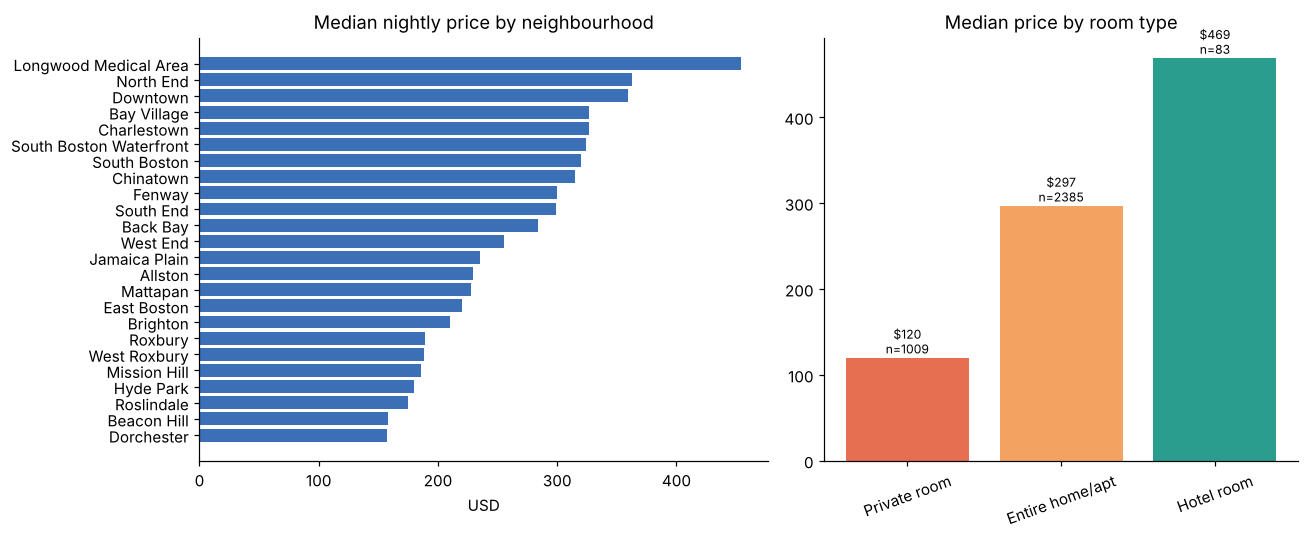

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1.2, 1]})
by_hood = df.groupby("neighbourhood")["price"].agg(["median", "count"]).sort_values("median")
ax[0].barh(by_hood.index, by_hood["median"], color="#3b6fb6")
ax[0].set_title("Median nightly price by neighbourhood"); ax[0].set_xlabel("USD")
rt = df.groupby("room_type")["price"].agg(["median", "count"]).sort_values("median")
ax[1].bar(rt.index, rt["median"], color=["#e76f51", "#f4a261", "#2a9d8f", "#3b6fb6"][:len(rt)])
ax[1].set_title("Median price by room type"); ax[1].tick_params(axis="x", rotation=20)
for i, (m, c) in enumerate(zip(rt["median"], rt["count"])):
    ax[1].text(i, m + 5, f"${m:.0f}\nn={c}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

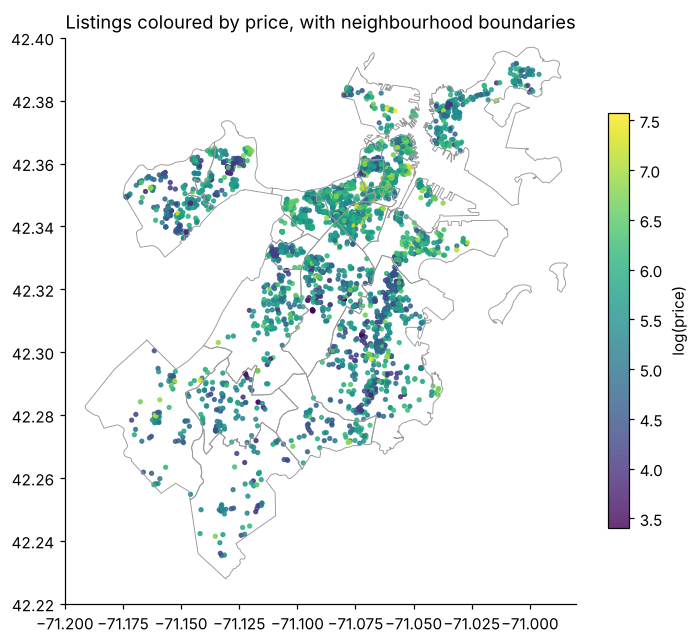

In [6]:
def draw_boundaries(ax):
    for f in geo["features"]:
        for poly in f["geometry"]["coordinates"]:
            ring = np.array(poly[0])
            ax.plot(ring[:, 0], ring[:, 1], color="#999", lw=0.6)

fig, ax = plt.subplots(figsize=(7.5, 7))
draw_boundaries(ax)
sc = ax.scatter(df["longitude"], df["latitude"], c=np.log(df["price"]), s=6, cmap="viridis", alpha=.8)
cb = plt.colorbar(sc, ax=ax, shrink=.7); cb.set_label("log(price)")
ax.set_title("Listings coloured by price, with neighbourhood boundaries")
ax.set_aspect(1 / np.cos(np.radians(42.33))); ax.set_xlim(-71.2, -70.98); ax.set_ylim(42.22, 42.40)
plt.show()

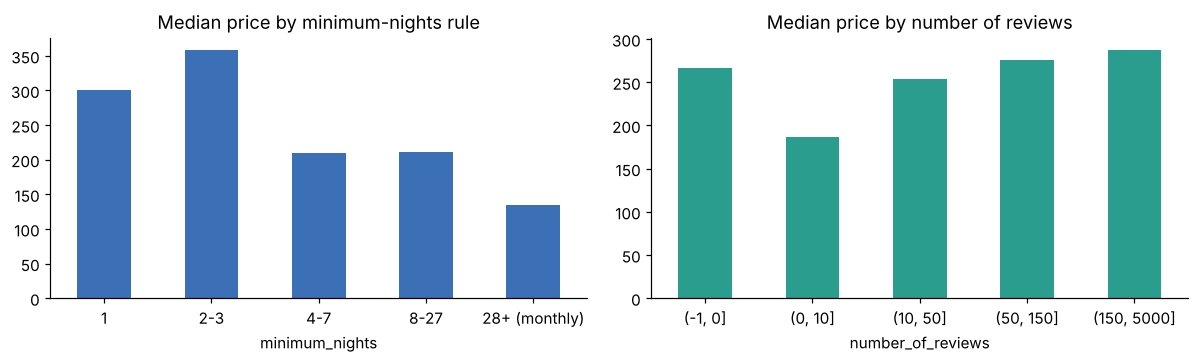

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
mn = df["minimum_nights"].fillna(1)
grp = pd.cut(mn, [0, 1, 3, 7, 27, 10000], labels=["1", "2-3", "4-7", "8-27", "28+ (monthly)"])
df.groupby(grp, observed=True)["price"].median().plot.bar(ax=ax[0], color="#3b6fb6", rot=0)
ax[0].set_title("Median price by minimum-nights rule")
df.groupby(pd.cut(df["number_of_reviews"], [-1, 0, 10, 50, 150, 5000]), observed=True)["price"].median().plot.bar(ax=ax[1], color="#2a9d8f", rot=0)
ax[1].set_title("Median price by number of reviews")
plt.tight_layout(); plt.show()

**What the exploration shows**
* **Room type** is the biggest driver: an entire home costs roughly 2-3x a private room.
* **Location matters**: Back Bay, the Waterfront, Downtown and Beacon Hill sit well above Dorchester, Mattapan and Hyde Park.
* **Short-stay listings (1-3 night minimum) charge more per night** than 28+ night monthly rentals, which are priced as discounted month-long stays.
* Listings with **no reviews** have a wider price spread, because many of them are new or not actively managed.

## 4. Feature engineering

Every candidate feature is something a host knows about their own listing, so the interface can ask for it:

| Candidate feature | Built from |
|---|---|
| `bedrooms`, `bedrooms_known` | Regex on title ("3BR", "2 bedroom", "Studio" = 0). Missing values set to 1 and flagged |
| `private_room`, `hotel_room`, `shared_room` | One-hot `room_type` (entire home = reference) |
| `log_min_nights`, `monthly` | log(1+minimum_nights); flag for 28+ nights |
| `log_reviews`, `reviews_per_month`, `number_of_reviews_ltm` | Track record and demand |
| `log_host_listings` | log(1 + host's listing count): professional operator signal |
| `availability_365` | Calendar openness |
| `licensed`, `exempt` | From `license` text |
| `dist_km` | Distance to Boston Common (42.3550, -71.0656) |
| `latitude`, `longitude` | Raw coordinates (useful for tree models) |
| `kw_*` | Title mentions parking / luxury-modern / view-rooftop / gym-pool-concierge / managed-furnished brand |
| `nb_*` | One-hot neighbourhood |

## 5. Variable screening: is each variable usable?

Before training, every candidate is checked four ways:
1. **Relationship with price.** Spearman rank correlation (monotonic) and mutual information (any shape) with log(price).
2. **Redundancy.** Pairwise correlation and the variance inflation factor (VIF). VIF > 10 means a variable is almost a copy of the others, which makes linear coefficients unstable.
3. **Support.** Indicators with very few 1s can't be learned reliably.
4. **Leakage.** A variable that lets the model recognise *who* the host is would inflate test scores, because big operators price all their units alike.

In [8]:
X_all = pf.build_features(df, NEIGHBOURHOODS, screened=False)
y = np.log(df["price"])
# shared_room is already all-zero after the pre-check merge, so it is screened out here automatically
cand = [c for c in X_all.columns if not c.startswith("nb_") and X_all[c].nunique() > 1]
screen = pd.DataFrame({
    "spearman": X_all[cand].corrwith(y, method="spearman"),
    "mutual_info": pd.Series(mutual_info_regression(X_all[cand], y, random_state=SEED), cand),
    "VIF": pf.vif(X_all[cand]),
    "ones_or_unique": [int(X_all[c].sum()) if X_all[c].nunique() <= 2 else X_all[c].nunique() for c in cand],
})
screen["rank_spearman"] = screen["spearman"].abs().rank(ascending=False).astype(int)
screen["rank_MI"] = screen["mutual_info"].rank(ascending=False).astype(int)
screen.sort_values("mutual_info", ascending=False).round(3)

,spearman,mutual_info,VIF,ones_or_unique,rank_spearman,rank_MI
log_host_listings,-0.014,0.427,1.372,40,20,1
longitude,0.133,0.328,1.648,2705,11,2
dist_km,-0.283,0.314,3.603,3052,4,3
latitude,0.189,0.314,2.328,2655,8,4
log_min_nights,-0.447,0.266,16.385,42,3,5
private_room,-0.514,0.234,1.356,1009,1,6
monthly,-0.512,0.187,15.112,1119,2,7
reviews_per_month,0.237,0.166,3.857,629,7,8
number_of_reviews_ltm,0.260,0.142,3.713,108,5,9
availability_365,-0.037,0.116,1.110,362,19,10


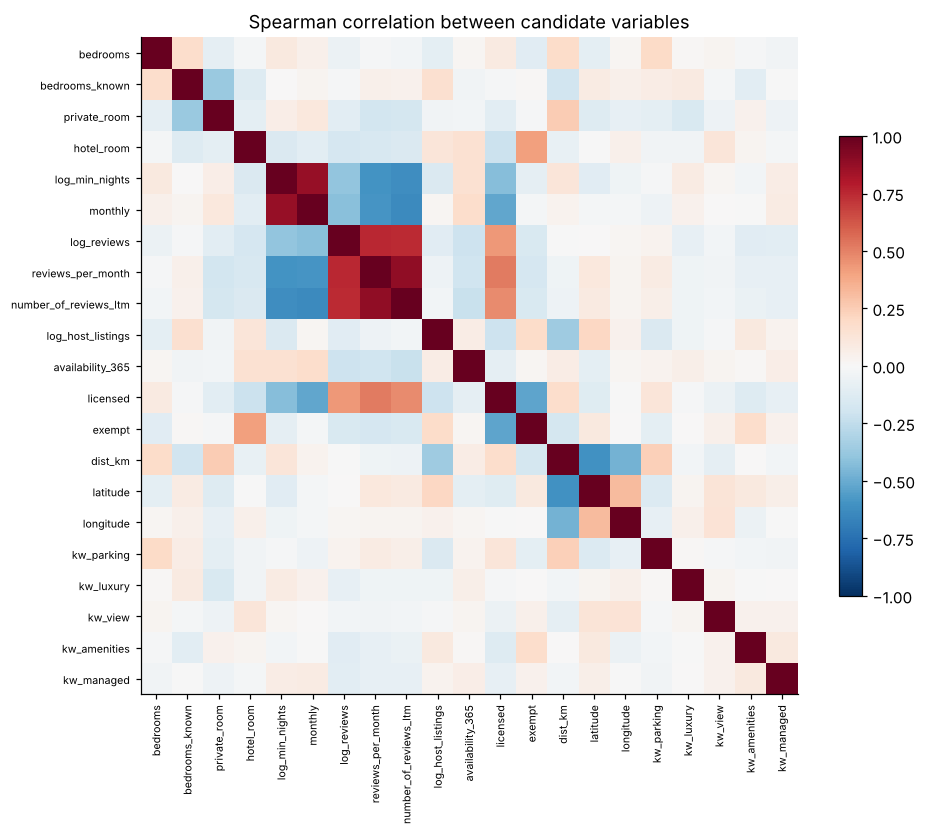

pairs with |r| > 0.7: [('log_min_nights', 'monthly', np.float64(0.87)), ('log_reviews', 'reviews_per_month', np.float64(0.76)), ('log_reviews', 'number_of_reviews_ltm', np.float64(0.75)), ('reviews_per_month', 'number_of_reviews_ltm', np.float64(0.89))]


In [9]:
C = X_all[cand].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7.5))
im = ax.imshow(C, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cand)), cand, rotation=90, fontsize=7); ax.set_yticks(range(len(cand)), cand, fontsize=7)
plt.colorbar(im, shrink=.7); ax.set_title("Spearman correlation between candidate variables"); plt.tight_layout(); plt.show()
high = [(a, b, round(C.loc[a, b], 2)) for i, a in enumerate(cand) for b in cand[i + 1:] if abs(C.loc[a, b]) > 0.7]
print("pairs with |r| > 0.7:", high)

**Leakage test for the host listing count.** `log_host_listings` has the **highest mutual information** with price but a Spearman correlation near **zero**. That pattern suggests it works as a host *fingerprint*: every listing of a 50-unit operator carries the value 50, so the model can learn that host's price level. We test this by comparing a random 5-fold CV with a **host-grouped** 5-fold CV, where all of a host's listings fall in the same fold.

In [10]:
groups = df["host_id"]
rf_probe = lambda: RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=2, max_features=0.5, random_state=SEED, n_jobs=-1)
def cv_rmse(Xm, grouped):
    cvk = GroupKFold(5) if grouped else KFold(5, shuffle=True, random_state=SEED)
    return -cross_val_score(rf_probe(), Xm, y, cv=cvk, groups=groups if grouped else None, scoring="neg_root_mean_squared_error").mean()
leak = pd.DataFrame({
    "random split": [cv_rmse(X_all, False)],
    "host-grouped split": [cv_rmse(X_all, True)],
}, index=["Random Forest, all candidate features"]).round(4)
print(f"{df['host_id'].nunique()} hosts; the largest has {df['host_id'].value_counts().iloc[0]} priced listings")
leak

1137 hosts; the largest has 87 priced listings


,random split,host-grouped split
"Random Forest, all candidate features",0.3666,0.4428


**Reading.** The error jumps when hosts can't be shared between training and test folds. The random split was **optimistic**: it let the model see a test listing's siblings from the same operator. A new host using the calculator is, by definition, a host the model has never seen. From here on, **every split is grouped by host**.

In [11]:
decisions = pd.DataFrame([
    ("monthly", "Drop", f"VIF {screen.loc['monthly', 'VIF']:.0f}: nearly a copy of log_min_nights (r = {C.loc['monthly', 'log_min_nights']:.2f}); log_min_nights carries the same information"),
    ("log_host_listings", "Replace with host_size_band", "Highest MI but ~0 correlation: acts as a host fingerprint. Bands (1 | 2-3 | 4-10 | 11-50 | 51+) keep the operator-size signal without identifying the host"),
    ("shared_room", "Drop", f"Only {int((listings.loc[listings['price'].notna(), 'room_type'] == 'Shared room').sum())} priced listings; merged into private room in the pre-check"),
    ("kw_managed", "Drop", f"Spearman {screen.loc['kw_managed', 'spearman']:.3f}, MI {screen.loc['kw_managed', 'mutual_info']:.3f}: no measurable signal"),
    ("log_reviews, reviews_per_month, number_of_reviews_ltm", "Keep all three", "Correlated (r up to 0.89) but VIF < 5: they describe different things (track record vs current demand)"),
    ("all other candidates", "Keep", "Clear relationship with price, VIF < 5, enough support"),
], columns=["variable", "decision", "evidence"])
decisions

,variable,decision,evidence
0,monthly,Drop,VIF 15: nearly a copy of log_min_nights (r = 0...
1,log_host_listings,Replace with host_size_band,Highest MI but ~0 correlation: acts as a host ...
2,shared_room,Drop,Only 4 priced listings; merged into private ro...
3,kw_managed,Drop,"Spearman 0.004, MI 0.005: no measurable signal"
4,"log_reviews, reviews_per_month, number_of_revi...",Keep all three,Correlated (r up to 0.89) but VIF < 5: they de...
5,all other candidates,Keep,"Clear relationship with price, VIF < 5, enough..."


In [12]:
X = pf.build_features(df, NEIGHBOURHOODS, screened=True)
FEATURES = list(X.columns)
print(f"{len(FEATURES)} features after screening (was {X_all.shape[1]})")
print(f"bedrooms parsed from title for {X['bedrooms_known'].mean():.0%} of listings")
print("max VIF among numeric features now:", pf.vif(X[[c for c in FEATURES if not c.startswith('nb_')]]).max().round(1))

43 features after screening (was 46)
bedrooms parsed from title for 39% of listings
max VIF among numeric features now: 3.8


### Does the pre-check and screening actually help?
Same model (Random Forest) and Lasso, host-grouped 5-fold CV, three versions of the pipeline. The "original" version is the pipeline before this recheck: only the price filter, all candidate features.

In [13]:
orig = listings[listings["price"].between(30, 2000)].copy()
X_orig = pf.build_features(orig.assign(reviews_per_month=orig["reviews_per_month"].fillna(0)),
                           sorted(official), screened=False)
y_orig = np.log(orig["price"])
lasso_probe = lambda: Pipeline([("s", StandardScaler()), ("m", LassoCV(alphas=np.logspace(-4, 0, 30), max_iter=50000))])
def cv_both(Xm, yy, g):
    out = {}
    for n, mk in [("Random Forest", rf_probe), ("Lasso", lasso_probe)]:
        out[n] = -cross_val_score(mk(), Xm, yy, cv=GroupKFold(5), groups=g, scoring="neg_root_mean_squared_error").mean()
    return out
ablation = pd.DataFrame({
    "1. Original (price filter only, all candidates)": cv_both(X_orig, y_orig, orig["host_id"]),
    "2. + pre-check cleaning": cv_both(X_all, y, groups),
    "3. + variable screening (final)": cv_both(X, y, groups),
}).T.round(4)
ablation.columns = [c + " CV RMSE(log)" for c in ablation.columns]
ablation

,Random Forest CV RMSE(log),Lasso CV RMSE(log)
"1. Original (price filter only, all candidates)",0.4400,0.4508
2. + pre-check cleaning,0.4428,0.4412
3. + variable screening (final),0.4333,0.4428


## 6. Experimental set-up

* **80/20 train-test split grouped by host** (seed 42): no host has listings in both sets. The test set is used **once**, at the end.
* **Host-grouped 5-fold cross-validation** on the training set for tuning and model comparison.
* Models predict **log(price)**; we convert back with `exp()` and report errors in **dollars**:
  * **MAE**: average dollars off per night (the easiest number for a host to understand)
  * **RMSE**: like MAE but penalises big misses more
  * **R² (log)**: share of price variation explained
  * **MAPE / within 20%**: relative accuracy (how often the suggestion is within ±20% of the actual price)

In [14]:
tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, groups))
X_train, X_test, y_train, y_test = X.iloc[tr_i], X.iloc[te_i], y.iloc[tr_i], y.iloc[te_i]
g_train = groups.iloc[tr_i]
assert not set(g_train) & set(groups.iloc[te_i])
cv = GroupKFold(5)
print("train", X_train.shape, "test", X_test.shape, "| hosts:", g_train.nunique(), "train,", groups.iloc[te_i].nunique(), "test")

def evaluate(name, y_true_log, y_pred_log):
    t, p = np.exp(y_true_log), np.exp(y_pred_log)
    return {
        "model": name,
        "MAE_$": mean_absolute_error(t, p),
        "RMSE_$": mean_squared_error(t, p) ** 0.5,
        "R2_log": r2_score(y_true_log, y_pred_log),
        "MAPE_%": np.mean(np.abs(p - t) / t) * 100,
        "within_20%": np.mean(np.abs(p - t) / t <= 0.2) * 100,
    }

train (2861, 43) test (616, 43) | hosts: 909 train, 228 test


## 7. Models

### 6.0 Baseline: neighbourhood × room-type median
The rule of thumb many hosts use: copy the median price of similar listings nearby. A model is only worth using if it beats this.

In [15]:
class GroupMedian(BaseEstimator, RegressorMixin):
    # Predict the median log-price of the (neighbourhood, room type) cell; fall back to room-type median.
    def _keys(self, X):
        hood = X[[c for c in X.columns if c.startswith("nb_")]].idxmax(axis=1)
        room = np.select([X["private_room"] == 1, X["hotel_room"] == 1], ["private", "hotel"], "entire")
        return hood.values, room
    def fit(self, X, y):
        h, r = self._keys(X); t = pd.DataFrame({"h": h, "r": r, "y": np.asarray(y)})
        self.cell_ = t.groupby(["h", "r"])["y"].median().to_dict()
        self.room_ = t.groupby("r")["y"].median().to_dict(); self.all_ = t["y"].median()
        return self
    def predict(self, X):
        h, r = self._keys(X)
        return np.array([self.cell_.get((a, b), self.room_.get(b, self.all_)) for a, b in zip(h, r)])

results, cv_scores, fitted, fit_time = [], {}, {}, {}

def run(name, model):
    t0 = time.time()
    scores = -cross_val_score(model, X_train, y_train, cv=cv, groups=g_train, scoring="neg_root_mean_squared_error")
    model.fit(X_train, y_train)
    fit_time[name] = time.time() - t0
    cv_scores[name] = scores; fitted[name] = model
    r = evaluate(name, y_test, model.predict(X_test)); r["CV_RMSE_log"] = scores.mean(); r["CV_std"] = scores.std()
    results.append(r)
    print(f"{name:18s} CV RMSE(log) = {scores.mean():.3f} ± {scores.std():.3f} | test MAE = ${r['MAE_$']:.0f}")
    return model

run("Baseline", GroupMedian())

Baseline           CV RMSE(log) = 0.635 ± 0.069 | test MAE = $146


Name,Type,Value
all_,float64,5.537
cell_,dict,"{('nb...on', 'entire'): 5.6240175061873385, ('nb...on', 'private'): 4.442651256490317, ('nb...ay', 'entire'): 5.680172609017068, ('nb...ay', 'hotel'): 6.150602768446279, ...}"
room_,dict,"{'entire': 5.703782474656201, 'hotel': 6.124683390894205, 'private': 4.727387818712341}"


### 6.1 Linear Regression (OLS)
Assumes log(price) is a **weighted sum** of the features. Each coefficient reads as "+x% price per unit". The model is transparent and fast, but it can't capture interactions such as "a monthly minimum stay matters more for entire homes".

In [16]:
ols = run("Linear Regression", Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]))

Linear Regression  CV RMSE(log) = 0.452 ± 0.042 | test MAE = $111


### 6.2 Lasso Regression (L1 regularisation)
Lasso is the same linear model with a penalty `α·Σ|β|` that **shrinks weak coefficients to exactly zero**, so it selects features automatically. `LassoCV` picks α by cross-validation.

In [17]:
lasso = run("Lasso", Pipeline([("scale", StandardScaler()),
                               ("model", LassoCV(alphas=np.logspace(-4, 0, 60), cv=5, max_iter=50000))]))
alpha = lasso.named_steps["model"].alpha_
coef = pd.Series(lasso.named_steps["model"].coef_, FEATURES)
print(f"chosen alpha = {alpha:.5f}; features set to zero: {(coef == 0).sum()} of {len(coef)}")
print("zeroed:", list(coef[coef == 0].index))

Lasso              CV RMSE(log) = 0.450 ± 0.043 | test MAE = $111
chosen alpha = 0.00142; features set to zero: 3 of 43
zeroed: ['nb_Bay Village', 'nb_Brighton', 'nb_Jamaica Plain']


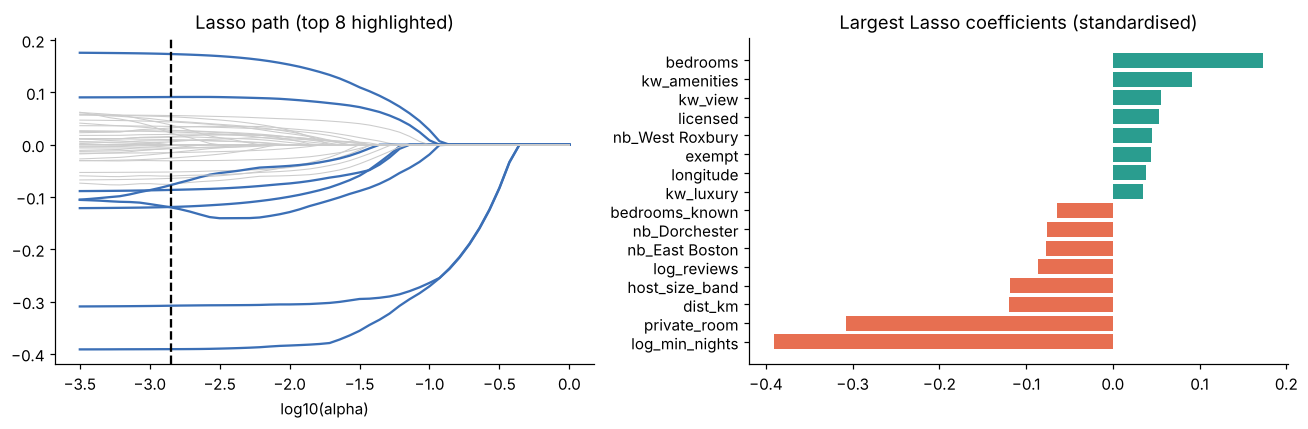

In [18]:
# Regularisation path: how coefficients shrink as alpha grows
Xs = lasso.named_steps["scale"].transform(X_train)
alphas, coefs, _ = lasso_path(Xs, y_train, alphas=np.logspace(-3.5, 0, 50))
top = np.argsort(-np.abs(coef.values))[:8]
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for i in range(coefs.shape[0]):
    ax[0].plot(np.log10(alphas), coefs[i], color="#3b6fb6" if i in top else "#ccc", lw=1.5 if i in top else .7)
ax[0].axvline(np.log10(alpha), ls="--", color="k"); ax[0].set_xlabel("log10(alpha)"); ax[0].set_title("Lasso path (top 8 highlighted)")
c = coef[coef != 0].sort_values(); c = pd.concat([c.head(8), c.tail(8)])
ax[1].barh(c.index, c.values, color=np.where(c > 0, "#2a9d8f", "#e76f51"))
ax[1].set_title("Largest Lasso coefficients (standardised)")
plt.tight_layout(); plt.show()

### 6.3 Random Forest
Hundreds of decision trees, each grown on a bootstrap sample with a random subset of features; the forest averages their predictions. It captures **non-linear effects and interactions** without needing scaling. We tune depth, leaf size and feature fraction with grid-search CV. The tree size is capped so the forest can be shipped to the browser.

In [19]:
rf_grid = GridSearchCV(
    RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1),
    {"max_depth": [10, 14], "min_samples_leaf": [2, 4], "max_features": [0.33, 0.5]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
rf_grid.fit(X_train, y_train, groups=g_train)
print("best RF params:", rf_grid.best_params_)
rf = run("Random Forest", RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1, **rf_grid.best_params_))

best RF params: {'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 2}


Random Forest      CV RMSE(log) = 0.449 ± 0.028 | test MAE = $104


### 6.4 Gradient Boosting
Trees are built **sequentially**, and each small tree corrects the errors of the ones before it. It is often the most accurate method on tabular data, but it is more sensitive to hyper-parameters (learning rate × number of trees × depth).

In [20]:
gb_grid = GridSearchCV(
    GradientBoostingRegressor(subsample=0.8, random_state=SEED),
    {"n_estimators": [300, 600], "learning_rate": [0.03, 0.06], "max_depth": [3, 4]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=-1)
gb_grid.fit(X_train, y_train, groups=g_train)
print("best GB params:", gb_grid.best_params_)
gb = run("Gradient Boosting", GradientBoostingRegressor(subsample=0.8, random_state=SEED, **gb_grid.best_params_))

best GB params: {'learning_rate': 0.03, 'max_depth': 4, 'n_estimators': 300}


Gradient Boosting  CV RMSE(log) = 0.447 ± 0.031 | test MAE = $105


## 8. Comparing the methods

In [21]:
res = pd.DataFrame(results).set_index("model")
res["train_time_s"] = pd.Series(fit_time)
res["interpretability"] = ["Very high", "High", "High (sparse)", "Medium", "Low-Medium"]
res[["CV_RMSE_log", "CV_std", "MAE_$", "RMSE_$", "R2_log", "MAPE_%", "within_20%", "train_time_s", "interpretability"]].round(3)

,CV_RMSE_log,CV_std,MAE_$,RMSE_$,R2_log,MAPE_%,within_20%,train_time_s,interpretability
model,,,,,,,,,
Baseline,0.635,0.069,146.439,233.261,0.216,51.812,27.435,0.051,Very high
Linear Regression,0.452,0.042,110.529,187.497,0.580,35.404,37.662,0.063,High
Lasso,0.450,0.043,110.646,187.919,0.581,35.253,37.662,0.395,High (sparse)
Random Forest,0.449,0.028,104.425,187.994,0.632,32.227,43.344,1.866,Medium
Gradient Boosting,0.447,0.031,105.018,186.880,0.633,32.380,42.045,8.373,Low-Medium


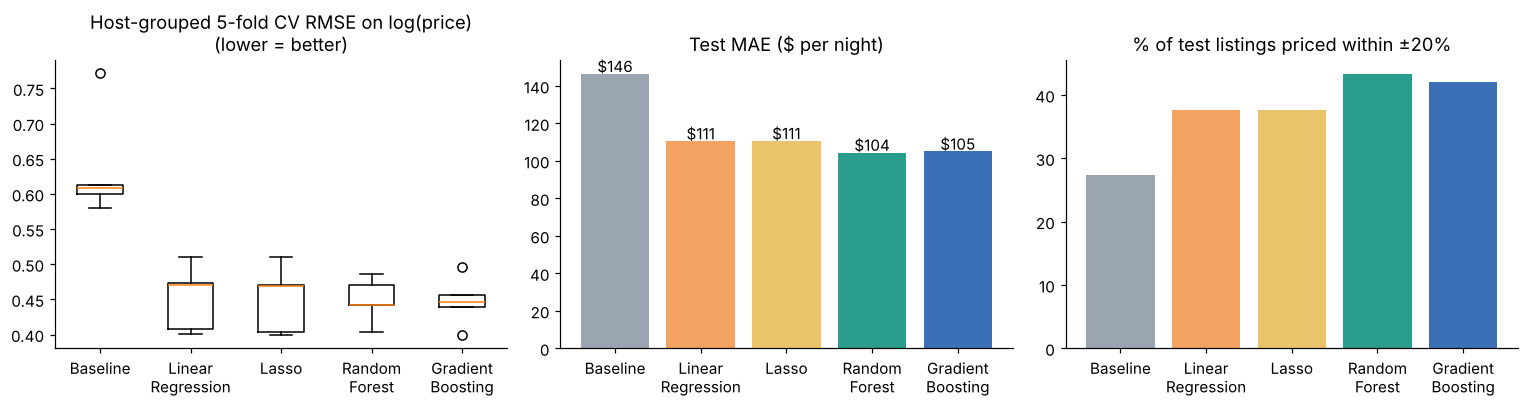

In [22]:
names = list(res.index)
colors = ["#9aa5b1", "#f4a261", "#e9c46a", "#2a9d8f", "#3b6fb6"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
ax[0].boxplot([cv_scores[n] for n in names]); ax[0].set_xticks(range(1, len(names) + 1), [n.replace(" ", "\n") for n in names])
ax[0].set_title("Host-grouped 5-fold CV RMSE on log(price)\n(lower = better)")
ax[1].bar(range(len(names)), res["MAE_$"], color=colors); ax[1].set_xticks(range(len(names)), [n.replace(" ", "\n") for n in names])
ax[1].set_title("Test MAE ($ per night)")
for i, v in enumerate(res["MAE_$"]): ax[1].text(i, v + 1, f"${v:.0f}", ha="center")
ax[2].bar(range(len(names)), res["within_20%"], color=colors); ax[2].set_xticks(range(len(names)), [n.replace(" ", "\n") for n in names])
ax[2].set_title("% of test listings priced within ±20%")
plt.tight_layout(); plt.show()

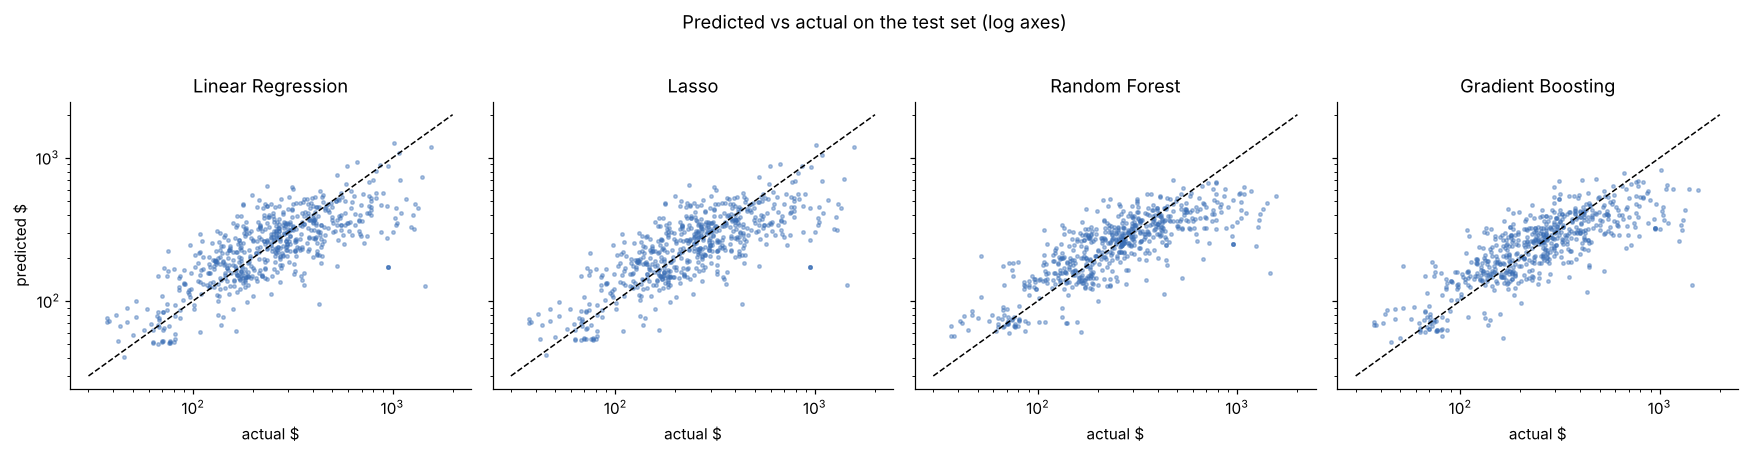

In [23]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True, sharey=True)
for ax, n in zip(axes, names[1:]):
    p = np.exp(fitted[n].predict(X_test)); t = np.exp(y_test)
    ax.scatter(t, p, s=5, alpha=.4, color="#3b6fb6"); ax.plot([30, 2000], [30, 2000], "k--", lw=1)
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_title(n); ax.set_xlabel("actual $")
axes[0].set_ylabel("predicted $"); plt.suptitle("Predicted vs actual on the test set (log axes)", y=1.02)
plt.tight_layout(); plt.show()

### Why the methods behave differently

| | Linear Regression | Lasso | Random Forest | Gradient Boosting |
|---|---|---|---|---|
| **Shape of relationship** | Straight-line, additive | Straight-line, additive | Any shape, interactions | Any shape, interactions |
| **Feature selection** | None | Automatic (L1 → zeros) | Implicit (splits) | Implicit (splits) |
| **Overfitting control** | None | α penalty | Bagging + leaf size | Learning rate + depth + subsampling |
| **Explainability** | Coefficient = % effect | Same, fewer terms | Feature importance | Feature importance |
| **Data needs** | Low | Low | Medium | Medium |

* **Linear vs Lasso perform almost identically.** After screening there are 43 features against 2,800+ training rows and no severe collinearity left, so overfitting is mild and the optimal α is small. Lasso's value is **simplicity**: it zeroes the weak features and keeps the same accuracy.
* **Honest evaluation shrinks the gap between linear and tree models.** With a random split, trees looked far ahead (CV RMSE about 0.37 vs 0.43), partly because they memorised big operators' price levels. With hosts kept apart, the four learned models are within cross-validation noise of each other. On the held-out hosts, the trees still lead on dollar error and R², because they capture interactions (for example, a long minimum stay cuts the price of an entire home in a prime area more than a private room) that linear models can't represent without hand-built terms.
* **Random Forest vs Gradient Boosting** are tied. The forest varies less from fold to fold, trains several times faster and needs less tuning.

In [24]:
# Selection rule: models whose CV RMSE is within one standard error of the best are treated as tied;
# among those, pick the most stable one (lowest fold-to-fold standard deviation).
se = res["CV_std"] / np.sqrt(5)
lowest = res["CV_RMSE_log"].idxmin()
tied = res[res["CV_RMSE_log"] <= res.loc[lowest, "CV_RMSE_log"] + se[lowest]]
best_name = tied["CV_std"].idxmin()
best = fitted[best_name]
print("lowest CV RMSE:", lowest, "| tied within 1 SE:", list(tied.index))
print("chosen (most stable of the tied models):", best_name)
print(res.loc[best_name, ["MAE_$", "R2_log", "MAPE_%", "within_20%"]].round(2).to_dict())
improvement = 1 - res.loc[best_name, "MAE_$"] / res.loc["Baseline", "MAE_$"]
print(f"MAE improvement over the 'copy the neighbourhood median' baseline: {improvement:.0%}")

lowest CV RMSE: Gradient Boosting | tied within 1 SE: ['Linear Regression', 'Lasso', 'Random Forest', 'Gradient Boosting']
chosen (most stable of the tied models): Random Forest
{'MAE_$': 104.43, 'R2_log': 0.63, 'MAPE_%': 32.23, 'within_20%': 43.34}
MAE improvement over the 'copy the neighbourhood median' baseline: 29%


### What drives price? (permutation importance on the best model)
Permutation importance measures how much test error grows when a feature's values are shuffled. It is model-agnostic and more reliable than impurity-based importance.

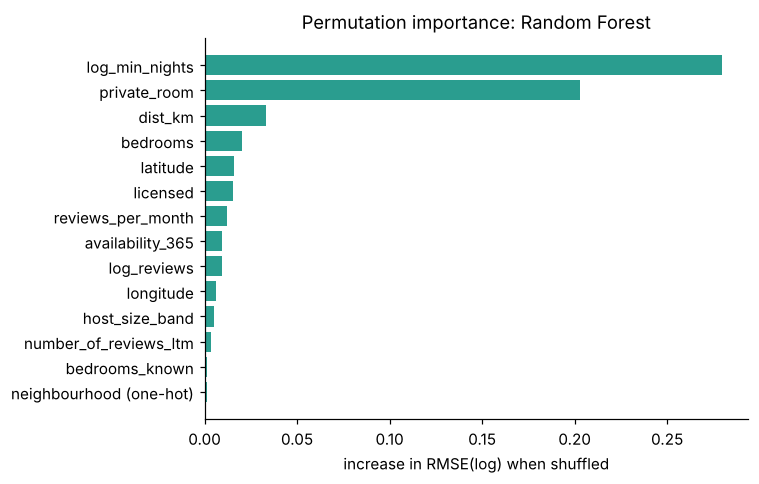

In [25]:
pi = permutation_importance(best, X_test, y_test, n_repeats=8, random_state=SEED, scoring="neg_root_mean_squared_error")
imp = pd.Series(pi.importances_mean, FEATURES)
# group the 26 neighbourhood dummies into one "neighbourhood" importance for readability
grouped = imp[[f for f in FEATURES if not f.startswith("nb_")]].copy()
grouped["neighbourhood (one-hot)"] = imp[[f for f in FEATURES if f.startswith("nb_")]].sum()
grouped = grouped.sort_values(ascending=True).tail(14)
plt.figure(figsize=(7, 4.5)); plt.barh(grouped.index, grouped.values, color="#2a9d8f")
plt.title(f"Permutation importance: {best_name}"); plt.xlabel("increase in RMSE(log) when shuffled"); plt.tight_layout(); plt.show()

In [26]:
# Lasso coefficients in plain language: % change in price, holding everything else fixed
raw = lasso.named_steps["model"].coef_ / lasso.named_steps["scale"].scale_
effects = pd.Series((np.exp(raw) - 1) * 100, FEATURES)
readable = effects[["private_room", "hotel_room", "log_min_nights", "host_size_band", "bedrooms", "kw_parking",
                    "kw_luxury", "kw_view", "licensed", "dist_km", "nb_Back Bay", "nb_Dorchester"]].round(1)
print("Lasso: % price effect of +1 unit of each feature")
readable.to_frame("% effect")

Lasso: % price effect of +1 unit of each feature


,% effect
private_room,-49.1
hotel_room,-14.3
log_min_nights,-25.4
host_size_band,-8.8
bedrooms,19.7
kw_parking,-5.3
kw_luxury,10.4
kw_view,28.1
licensed,11.9
dist_km,-4.0


## 9. Which method should a host use?

**Recommendation: Random Forest as the pricing engine, with Lasso as the explanation layer.**

* Under host-grouped cross-validation the learned models are statistically tied. The forest is the most stable of them, and on the held-out hosts it has the lowest dollar error and, with gradient boosting, the highest R².
* Every learned model beats the neighbourhood-median rule of thumb by a wide margin.
* Lasso is slightly less accurate on new hosts, but its coefficients say *why*: "−49% for a private room", "+20% per bedroom". The interface shows both.

The cell below turns the chosen model into a pricing function for one listing.

In [27]:
# Residual quantiles on the test set -> an honest 80% price band around any prediction
resid = y_test - best.predict(X_test)
band = (float(np.quantile(resid, 0.10)), float(np.quantile(resid, 0.90)))

def price_listing(neighbourhood, room_type, bedrooms=1, minimum_nights=2, number_of_reviews=0,
                  reviews_per_month=0.0, number_of_reviews_ltm=0, host_listings=1, availability_365=180,
                  license="STR-000000", title="", lat=None, lon=None):
    sub = df[df["neighbourhood"] == neighbourhood]
    if sub.empty:                                   # e.g. Harbor Islands has no listings
        sub = df
    row = pd.DataFrame([{
        "name": title + (" studio" if bedrooms == 0 else f" {bedrooms}BR"),
        "neighbourhood": neighbourhood, "room_type": room_type,
        "latitude": lat if lat is not None else sub["latitude"].median(),
        "longitude": lon if lon is not None else sub["longitude"].median(),
        "minimum_nights": minimum_nights, "number_of_reviews": number_of_reviews,
        "reviews_per_month": reviews_per_month, "number_of_reviews_ltm": number_of_reviews_ltm,
        "calculated_host_listings_count": host_listings, "availability_365": availability_365,
        "license": license}])
    x = pf.build_features(row, NEIGHBOURHOODS)[FEATURES]
    out = {n: float(np.exp(m.predict(x))[0]) for n, m in fitted.items()}
    out["range_low"], out["range_high"] = np.exp(np.log(out[best_name]) + np.array(band))
    return {k: round(v) for k, v in out.items()}

example = price_listing("South End", "Entire home/apt", bedrooms=2, minimum_nights=2, number_of_reviews=25,
                        reviews_per_month=1.5, number_of_reviews_ltm=10, title="Modern 2BR with parking")
example

{'Baseline': 299,
 'Linear Regression': 542,
 'Lasso': 536,
 'Random Forest': 489,
 'Gradient Boosting': 628,
 'range_low': 307,
 'range_high': 862}

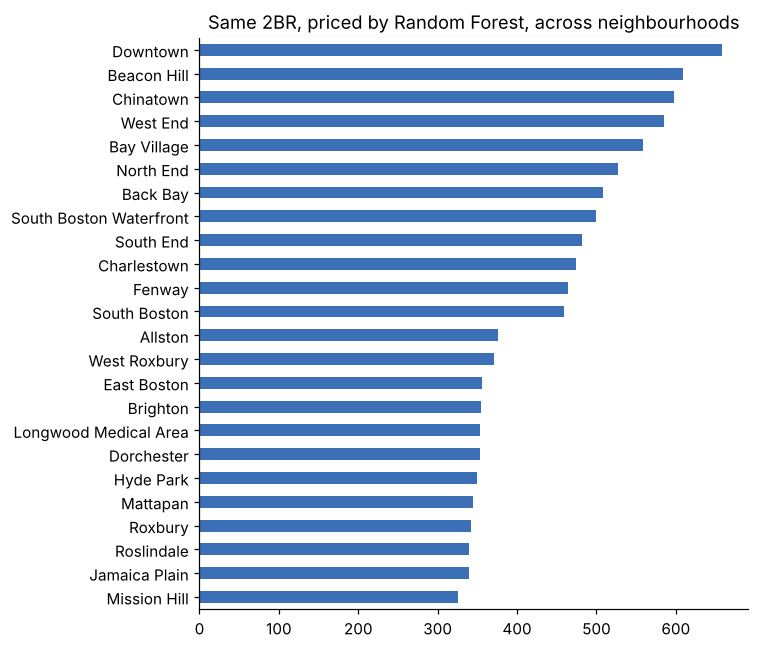

In [28]:
# Same listing priced in every neighbourhood: where does location add the most value?
comp = pd.Series({h: price_listing(h, "Entire home/apt", 2, 2, 25, 1.5, 10)[best_name] for h in df["neighbourhood"].unique()}).sort_values()
comp.plot.barh(figsize=(7, 6), color="#3b6fb6", title=f"Same 2BR, priced by {best_name}, across neighbourhoods"); plt.tight_layout(); plt.show()

## 10. Export for the portfolio interface
The cell below refits every model on **all** cleaned data (train + test) and serialises it to `interface/data.js` (metrics and chart data) and `interface/models.js` (the trained models):
* Linear Regression and Lasso → intercept, coefficients and scaler mean/std
* Random Forest and Gradient Boosting → compact pre-order tree arrays (feature, threshold-or-value, right child)
* Baseline → median lookup table
* Plus the evaluation metrics, importances, neighbourhood stats and simplified boundaries for the charts and map.

The JavaScript in `interface/index.html` re-implements `build_features` and tree traversal, so the browser gives the same prediction as Python for the same input. `scripts/verify_js.js` checks this.

In [29]:
FINE = {FEATURES.index(c) for c in ("latitude", "longitude", "dist_km")}

def export_tree(t, scale=1.0):
    # Compact pre-order encoding: the left child of node i is always i+1 (sklearn depth-first builder),
    # so we only store f (feature, -1 = leaf) and x (threshold, or leaf value).
    tr = t.tree_
    leaf = tr.children_left == -1
    assert np.all(tr.children_left[~leaf] == np.arange(tr.node_count)[~leaf] + 1)
    # coordinate splits need 9 significant digits; other thresholds 6; leaf values (log price) 5
    x = [float(f"{v * scale:.5g}") if is_leaf else float(f"{th:.9g}" if f in FINE else f"{th:.6g}")
         for v, th, f, is_leaf in zip(tr.value[:, 0, 0], tr.threshold, tr.feature, leaf)]
    # right-child indexes are not stored: the browser rebuilds them from the pre-order layout
    return {"f": np.where(leaf, -1, tr.feature).tolist(), "x": x}

def export_linear(pipe):
    m, s = pipe.named_steps["model"], pipe.named_steps["scale"]
    return {"intercept": float(m.intercept_), "coef": np.round(m.coef_, 6).tolist(),
            "mean": np.round(s.mean_, 6).tolist(), "scale": np.round(s.scale_, 6).tolist()}

# refit on all data with the tuned settings
final = {
    "Baseline": GroupMedian().fit(X, y),
    "Linear Regression": Pipeline([("scale", StandardScaler()), ("model", LinearRegression())]).fit(X, y),
    "Lasso": Pipeline([("scale", StandardScaler()), ("model", LassoCV(alphas=[alpha], cv=5))]).fit(X, y),
    "Random Forest": RandomForestRegressor(n_estimators=150, random_state=SEED, n_jobs=-1, **rf_grid.best_params_).fit(X, y),
    "Gradient Boosting": GradientBoostingRegressor(subsample=0.8, random_state=SEED, **gb_grid.best_params_).fit(X, y),
}
gbf = final["Gradient Boosting"]
models_json = {
    "Baseline": {"cell": {f"{h}|{r}": round(v, 5) for (h, r), v in final["Baseline"].cell_.items()},
                 "room": {k: round(v, 5) for k, v in final["Baseline"].room_.items()}, "all": final["Baseline"].all_},
    "Linear Regression": export_linear(final["Linear Regression"]),
    "Lasso": export_linear(final["Lasso"]),
    "Random Forest": {"trees": [export_tree(e) for e in final["Random Forest"].estimators_]},
    "Gradient Boosting": {"init": float(gbf.init_.constant_[0][0]),
                          "trees": [export_tree(e[0], gbf.learning_rate) for e in gbf.estimators_]},
}

# reference predictions so the JS port can be verified
ref_idx = X.sample(200, random_state=1).index
reference = {"X": X.loc[ref_idx].values.tolist(),
             "pred": {n: np.round(m.predict(X.loc[ref_idx]), 5).tolist() for n, m in final.items()}}

In [30]:
def simplify(coords, step=3):
    return [[round(x, 4), round(y, 4)] for x, y in coords[::step]] + [[round(coords[-1][0], 4), round(coords[-1][1], 4)]]

geo_small = {"type": "FeatureCollection", "features": [
    {"type": "Feature", "properties": {"name": f["properties"]["neighbourhood"]},
     "geometry": {"type": "MultiPolygon", "coordinates": [[simplify(poly[0])] for poly in f["geometry"]["coordinates"] if len(poly[0]) > 8]}}
    for f in geo["features"]]}

hood_stats = df.groupby("neighbourhood").agg(
    median=("price", "median"), q25=("price", lambda s: s.quantile(.25)), q75=("price", lambda s: s.quantile(.75)),
    count=("price", "size"), lat=("latitude", "median"), lon=("longitude", "median"),
    share_entire=("room_type", lambda s: (s == "Entire home/apt").mean())).round(4)
room_stats = df.groupby("room_type")["price"].agg(["median", "count"]).round(1)

test_scatter = {n: {"actual": np.round(np.exp(y_test), 0).tolist()[:400],
                    "pred": np.round(np.exp(fitted[n].predict(X_test)), 0).tolist()[:400]} for n in names}
hist_counts, hist_edges = np.histogram(np.log(df["price"]), bins=40)

bundle = {
    "meta": {"rows_raw": int(n0), "rows_priced": int(n1), "rows_model": int(n2), "price_cap": upper,
             "n_train": len(X_train), "n_test": len(X_test), "n_features": len(FEATURES),
             "split": "host-grouped", "best": best_name, "band_log": band, "alpha": float(alpha), "center": pf.CENTER,
             "rf_params": rf_grid.best_params_, "gb_params": gb_grid.best_params_,
             "lasso_zeroed": list(coef[coef == 0].index),
             "bedrooms_known_share": float(X["bedrooms_known"].mean()),
             "baseline_improvement": float(improvement)},
    "features": FEATURES, "keywords": pf.KEYWORDS, "neighbourhoods": NEIGHBOURHOODS,
    "host_bands": [b for b in pf.HOST_BANDS if np.isfinite(b)], "hood_merge": pf.HOOD_MERGE, "room_merge": pf.ROOM_MERGE,
    "precheck": precheck_report.to_dict(orient="records"),
    "screening": screen.reset_index().rename(columns={"index": "feature"}).round(4).replace({np.inf: None}).to_dict(orient="records"),
    "decisions": decisions.to_dict(orient="records"),
    "leak": {"random": float(leak.iloc[0, 0]), "grouped": float(leak.iloc[0, 1]), "hosts": int(df["host_id"].nunique()),
             "largest_host": int(df["host_id"].value_counts().iloc[0])},
    "ablation": ablation.reset_index().rename(columns={"index": "pipeline"}).to_dict(orient="records"),
    "high_corr_pairs": [[a, b, float(r)] for a, b, r in high],
    "metrics": res.drop(columns=["interpretability"]).round(4).reset_index().to_dict(orient="records"),
    "cv_scores": {n: np.round(v, 4).tolist() for n, v in cv_scores.items()},
    "importance": grouped.sort_values(ascending=False).round(5).to_dict(),
    "lasso_effects": effects.round(2).to_dict(),
    "hood_stats": hood_stats.reset_index().to_dict(orient="records"),
    "room_stats": room_stats.reset_index().to_dict(orient="records"),
    "price_hist": {"counts": hist_counts.tolist(), "edges": np.round(np.exp(hist_edges), 1).tolist()},
    "test_scatter": test_scatter,
    "geo": geo_small,
}
OUT.mkdir(exist_ok=True)
# Two files: data.js (metrics, charts, map: small, loads first) and models.js (the trained trees)
payload = json.dumps(bundle, separators=(",", ":"))
(OUT / "data.js").write_text("window.PRICING = " + payload + ";\n")
models_payload = json.dumps({"snapshot": models_json, "snapshot_reference": reference}, separators=(",", ":"))
(OUT / "models.js").write_text("window.PRICING_MODELS = " + models_payload + ";\n")
print(f"wrote data.js ({len(payload) / 1e6:.2f} MB) and models.js ({len(models_payload) / 1e6:.2f} MB)")

wrote data.js (0.24 MB) and models.js (1.16 MB)


## 11. Limitations & next steps
* **Advertised price ≠ booked price.** The model learns what hosts *ask*, not what guests *pay*. Adding calendar/occupancy data would let us optimise revenue, not just match the market.
* **Missing property attributes.** Bedrooms come from titles for only part of the listings; bathrooms, capacity, amenities and review scores from the detailed file would cut the error further.
* **Host effects are real but unusable.** Much of the price variation is "who the host is". A new host can't be priced from that, which is why honest (host-grouped) error is higher than a random split suggests.
* **No seasonality.** This is one snapshot. Boston prices peak around graduation, marathon and fall foliage; a calendar-based model would add date effects.
* **Prices change over time.** Retrain on each new Inside Airbnb release (quarterly).